# Anomaly candidates across all three cameras — 1 September 2026

Compare s1 (highschool_13 NW), s2 (corbins_12 NW), and s3 (frantz_9 NW) in **48 half-hour windows**. Every camera is tested against the other two; flags identify a **camera/window**, not an individual vehicle or row.

Use the same selected approaches and September 1 file as `comparison.ipynb`. Count rows in 30-second bins by default, including repeated request updates. Set `COUNT_MODE = "first_seen_requests"` to count first-seen request IDs instead. Differences in update rates can create distribution differences without a physical sensor fault.

Align to the middle camera: shift s1 by +30 seconds and s3 by −30 seconds. Keep the original stored clock. Each half-hour ECDF has 60 count samples (59 at the day's boundaries). ECDFs compare count distributions, not the order of observations; they can miss timing anomalies that preserve the distribution.

**Flags are exploratory candidates, not confirmed faults or probabilities.** The thresholds below are editable, uncalibrated starting values. With only three cameras, two similarly faulty sensors may make the healthy one look unusual. All-silent windows are reported separately; zero activity is not proof of a sensor failure.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DAY = "2026-09-01"
COUNT_MODE = "rows"  # Or "first_seen_requests" to remove repeated request updates.
BIN = "30s"
WINDOW = "30min"
TRAVEL_SECONDS = 30

# Editable candidate-flag thresholds (not calibrated against labeled faults).
SCORE_THRESHOLD = 0.15
REFERENCE_KS_MAX = 0.15  # The other two sensors must agree at least this closely.

# Works when launched from the notebook folder or the mobility workspace.
DATA_FILE = next(
    (folder / f"{DAY}.parquet" for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / f"{DAY}.parquet").is_file()),
    None,
)
if DATA_FILE is None:
    raise FileNotFoundError(f"Set DATA_FILE to the location of {DAY}.parquet")

cameras = pd.DataFrame([
    ["s1", "bridge.highschool_13", "SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw", "23.13", TRAVEL_SECONDS],
    ["s2", "bridge.corbins_12", "SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw", "13.12", 0],
    ["s3", "bridge.frantz_9", "SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw", "12.9", -TRAVEL_SECONDS],
], columns=["camera", "intersection", "sensor_id", "incoming_link", "shift_seconds"])
display(cameras)
print("Reading:", DATA_FILE)

,camera,intersection,sensor_id,incoming_link,shift_seconds
0,s1,bridge.highschool_13,SENSOR-bridge.highschool_13-fc_du_bridge.highs...,23.13,30
1,s2,bridge.corbins_12,SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw,13.12,0
2,s3,bridge.frantz_9,SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw,12.9,-30


Reading: /home/michal/mobility/2026-09-01.parquet


## Select the cameras and approaches

Strip the changing object/counter suffix from `sourceId`, preserving the location and NW direction. Require both the camera's own intersection and the specified incoming link, so forwarded records at other junctions and other approaches do not inflate the comparison. `REMOTE_SENSOR`, `NTCIP_CALL`, and `STARVATION` records are excluded. The audit shows records removed by the approach filter.

In [2]:
raw = pd.read_parquet(
    DATA_FILE,
    columns=["timestamp", "intersection_id", "source", "sourceId", "incomingLink_id", "id"],
    filters=[("intersection_id", "in", cameras["intersection"].tolist()), ("source", "==", "SENSOR")],
)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw["sensor_id"] = raw["sourceId"].str.replace(
    r"^(SENSOR-.*_(?:ne|nw|se|sw|n|e|s|w))\d+.*$", r"\1", regex=True
)
start = pd.Timestamp(DAY)
end = start + pd.Timedelta(days=1)
raw = raw[(raw["timestamp"] >= start) & (raw["timestamp"] < end)]

streams = {}
audit_rows = []
if COUNT_MODE not in ["rows", "first_seen_requests"]:
    raise ValueError("COUNT_MODE must be rows or first_seen_requests")
for camera in cameras.itertuples(index=False):
    selected = raw[(raw["intersection_id"] == camera.intersection)
                   & (raw["sensor_id"] == camera.sensor_id)].copy()
    approach = selected[selected["incomingLink_id"] == camera.incoming_link].sort_values("timestamp")
    events = approach.copy()
    if COUNT_MODE == "first_seen_requests":
        events = events.dropna(subset=["id"]).drop_duplicates("id", keep="first")
    streams[camera.camera] = events
    audit_rows.append({
        "camera": camera.camera, "camera_rows": len(selected),
        "excluded_other_links": len(selected) - len(approach),
        "selected_rows": len(approach), "distinct_request_ids": approach["id"].nunique(),
        "missing_request_ids": approach["id"].isna().sum(),
        "counted_events": len(events), "first_record": approach["timestamp"].min(),
        "last_record": approach["timestamp"].max(),
    })
audit = pd.DataFrame(audit_rows).set_index("camera")
display(audit)
if (audit["counted_events"] == 0).any():
    print("Warning: at least one selected camera has no records; check selection and data availability.")

,camera_rows,excluded_other_links,selected_rows,distinct_request_ids,missing_request_ids,counted_events,first_record,last_record
camera,,,,,,,,
s1,19814,4,19810,15872,0,19810,2026-09-01 00:00:00.101,2026-09-01 23:59:53.894
s2,21950,108,21842,17520,0,21842,2026-09-01 00:00:04.762,2026-09-01 23:59:57.627
s3,30804,133,30671,18136,0,30671,2026-09-01 00:00:03.903,2026-09-01 23:59:56.882


## Align the count streams

For example, s1 at 12:00:00, s2 at 12:00:30, and s3 at 12:01:00 all align to 12:00:30. Empty bins inside the file's nominal day count as zero; without sensor heartbeat data, zero cannot distinguish no traffic from missing reporting. The first and last half-hours have 59 common bins; interior windows have 60.

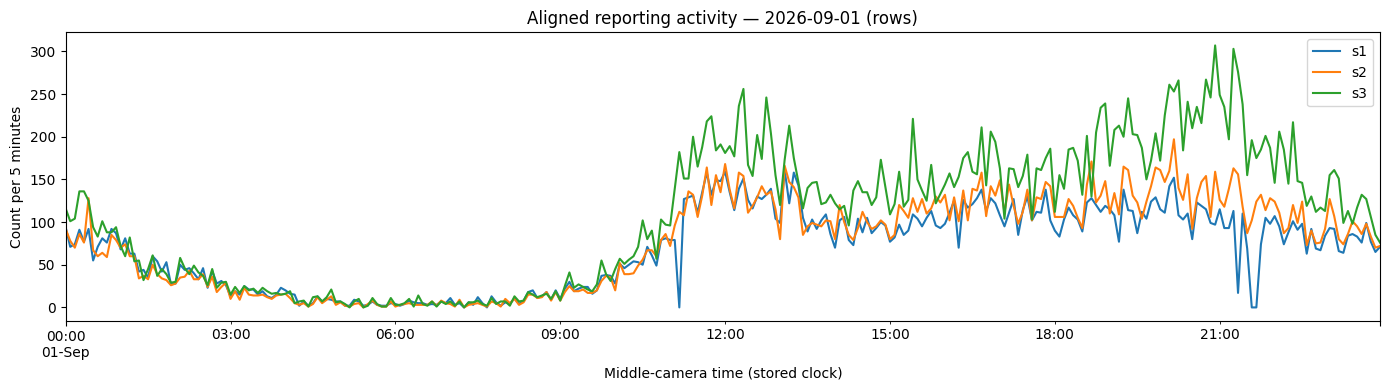

In [3]:
bin_width = pd.Timedelta(BIN)
grid = pd.date_range(start, end, freq=BIN, inclusive="left")
aligned = pd.DataFrame(index=grid)
for camera in cameras.itertuples(index=False):
    shift = pd.Timedelta(seconds=camera.shift_seconds)
    times = streams[camera.camera]["timestamp"] + shift
    counts = times.dt.floor(BIN).value_counts().reindex(grid, fill_value=0).sort_index()
    # A complete bin must fall within the shifted source day's coverage.
    available = (grid >= start + shift) & (grid + bin_width <= end + shift)
    aligned[camera.camera] = counts.astype(float).where(available)
aligned.index.name = "middle_camera_time"

aligned.resample("5min").sum(min_count=1).plot(figsize=(14, 4))
plt.title(f"Aligned reporting activity — {DAY} ({COUNT_MODE})")
plt.xlabel("Middle-camera time (stored clock)")
plt.ylabel("Count per 5 minutes")
plt.tight_layout()
plt.show()

## Symmetric comparison: each camera against the other two

KS distance is the largest vertical gap between two ECDFs, from 0 (same empirical distribution) to 1 (separated distributions).

For camera **i**, with the other cameras **j** and **k**:

`score_i = max(0, min(KS(i,j), KS(i,k)) - KS(j,k))`

Flag camera i when **score_i ≥ SCORE_THRESHOLD** and **KS(j,k) ≤ REFERENCE_KS_MAX**. The first condition requires i to disagree with both references; the second requires those references to agree. We report all three scores and all pairwise distances, rather than forcing a single camera to be faulty. If no pair agrees, attribution is marked inconclusive. No p-values are used: count samples can be tied and temporally dependent.

In [4]:
def ks_distance(a, b):
    a, b = np.sort(np.asarray(a)), np.sort(np.asarray(b))
    if len(a) == 0 or len(b) == 0:
        return np.nan
    values = np.unique(np.concatenate([a, b]))
    fa = np.searchsorted(a, values, side="right") / len(a)
    fb = np.searchsorted(b, values, side="right") / len(b)
    return float(np.max(np.abs(fa - fb)))


def score_and_flag(distance_to_first, distance_to_second, reference_distance):
    score = max(0.0, min(distance_to_first, distance_to_second) - reference_distance)
    flag = score >= SCORE_THRESHOLD and reference_distance <= REFERENCE_KS_MAX
    return score, flag


assert 0 < SCORE_THRESHOLD <= 1
assert 0 <= REFERENCE_KS_MAX <= 1
sensors = ["s1", "s2", "s3"]
window_rows, sensor_rows = [], []
for window_start in pd.date_range(start, end, freq=WINDOW, inclusive="left"):
    window_end = window_start + pd.Timedelta(WINDOW)
    window = aligned.loc[(aligned.index >= window_start) & (aligned.index < window_end)]
    common = window.dropna()
    row = {"window_start": window_start, "window_end": window_end,
           "common_bins": len(common), "coverage_fraction": len(common) / len(window)}
    distances = {(a, b): ks_distance(common[a], common[b])
                 for a, b in [("s1", "s2"), ("s1", "s3"), ("s2", "s3")]}
    row.update({f"ks_{a}_{b}": d for (a, b), d in distances.items()})
    all_silent = not common.empty and common.to_numpy().sum() == 0
    flagged = []
    for sensor in sensors:
        others = [s for s in sensors if s != sensor]
        d1 = distances[tuple(sorted([sensor, others[0]]))]
        d2 = distances[tuple(sorted([sensor, others[1]]))]
        reference = distances[tuple(sorted(others))]
        score, flag = (np.nan, False) if common.empty else score_and_flag(d1, d2, reference)
        mean = common[sensor].mean()
        reference_mean = common[others].mean().mean()
        direction = "fewer" if mean < reference_mean else "more" if mean > reference_mean else "same_mean"
        row[f"{sensor}_score"] = score
        row[f"{sensor}_flag"] = flag
        row[f"{sensor}_total"] = int(common[sensor].sum()) if not common.empty else np.nan
        row[f"{sensor}_mean"] = mean
        if flag:
            flagged.append(sensor)
        sensor_rows.append({
            "window_start": window_start, "window_end": window_end, "sensor": sensor,
            "common_bins": len(common), "score": score, "flag": flag,
            "ks_to_" + others[0]: d1, "ks_to_" + others[1]: d2,
            "reference_ks": reference, "mean_count": mean,
            "reference_mean": reference_mean,
            "mean_ratio": mean / reference_mean if reference_mean > 0 else np.nan,
            "zero_fraction": common[sensor].eq(0).mean() if not common.empty else np.nan,
            "direction": direction, "all_silent": all_silent,
        })
    row["flagged_sensors"] = ", ".join(flagged) if flagged else "none"
    row["status"] = ("no_common_coverage" if common.empty else "all_silent" if all_silent
                     else "candidate_anomaly" if flagged
                     else "inconclusive_no_pair_agrees" if min(distances.values()) > REFERENCE_KS_MAX
                     else "no_flag")
    window_rows.append(row)
metrics = pd.DataFrame(window_rows)
sensor_metrics = pd.DataFrame(sensor_rows)
with pd.option_context("display.max_rows", 48, "display.max_columns", None):
    display(metrics.round(4))
print("Flagged half-hours per camera:")
display(sensor_metrics.groupby("sensor")["flag"].sum().rename("flagged_windows").to_frame())

,window_start,window_end,common_bins,coverage_fraction,ks_s1_s2,ks_s1_s3,ks_s2_s3,s1_score,s1_flag,s1_total,s1_mean,s2_score,s2_flag,s2_total,s2_mean,s3_score,s3_flag,s3_total,s3_mean,flagged_sensors,status
0,2026-09-01 00:00:00,2026-09-01 00:30:00,59,0.9833,0.1186,0.2881,0.2373,0.0000,False,499,8.4576,0.0000,False,519,8.7966,0.1186,False,703,11.9153,none,no_flag
1,2026-09-01 00:30:00,2026-09-01 01:00:00,60,1.0000,0.1667,0.1167,0.2000,0.0000,False,462,7.7000,0.0500,False,414,6.9000,0.0000,False,548,9.1333,none,no_flag
2,2026-09-01 01:00:00,2026-09-01 01:30:00,60,1.0000,0.0833,0.1000,0.1167,0.0000,False,361,6.0167,0.0000,False,335,5.5833,0.0167,False,355,5.9167,none,no_flag
3,2026-09-01 01:30:00,2026-09-01 02:00:00,60,1.0000,0.2333,0.1167,0.1333,0.0000,False,271,4.5167,0.0167,False,214,3.5667,0.0000,False,256,4.2667,none,no_flag
4,2026-09-01 02:00:00,2026-09-01 02:30:00,60,1.0000,0.1667,0.1167,0.1667,0.0000,False,241,4.0167,0.0500,False,208,3.4667,0.0000,False,263,4.3833,none,no_flag
5,2026-09-01 02:30:00,2026-09-01 03:00:00,60,1.0000,0.1000,0.1000,0.1500,0.0000,False,197,3.2833,0.0000,False,170,2.8333,0.0000,False,190,3.1667,none,no_flag
6,2026-09-01 03:00:00,2026-09-01 03:30:00,60,1.0000,0.1167,0.0833,0.2000,0.0000,False,114,1.9000,0.0333,False,90,1.5000,0.0000,False,123,2.0500,none,no_flag
7,2026-09-01 03:30:00,2026-09-01 04:00:00,60,1.0000,0.2000,0.1333,0.1000,0.0333,False,96,1.6000,0.0000,False,80,1.3333,0.0000,False,107,1.7833,none,no_flag
8,2026-09-01 04:00:00,2026-09-01 04:30:00,60,1.0000,0.1333,0.0500,0.1000,0.0000,False,62,1.0333,0.0500,False,41,0.6833,0.0000,False,56,0.9333,none,no_flag
9,2026-09-01 04:30:00,2026-09-01 05:00:00,60,1.0000,0.0333,0.1167,0.1167,0.0000,False,51,0.8500,0.0000,False,46,0.7667,0.0833,False,71,1.1833,none,no_flag


,flagged_windows
sensor,
s1,0
s2,0
s3,7


Flagged half-hours per camera:


## Overlaid ECDFs for all 48 windows

The legend marks candidate cameras with `FLAG`. Flagged curves are thicker and their panels have a red title. A difference can be caused by reporting behavior or actual traffic, so review the shapes and the two reference cameras before interpreting a flag.

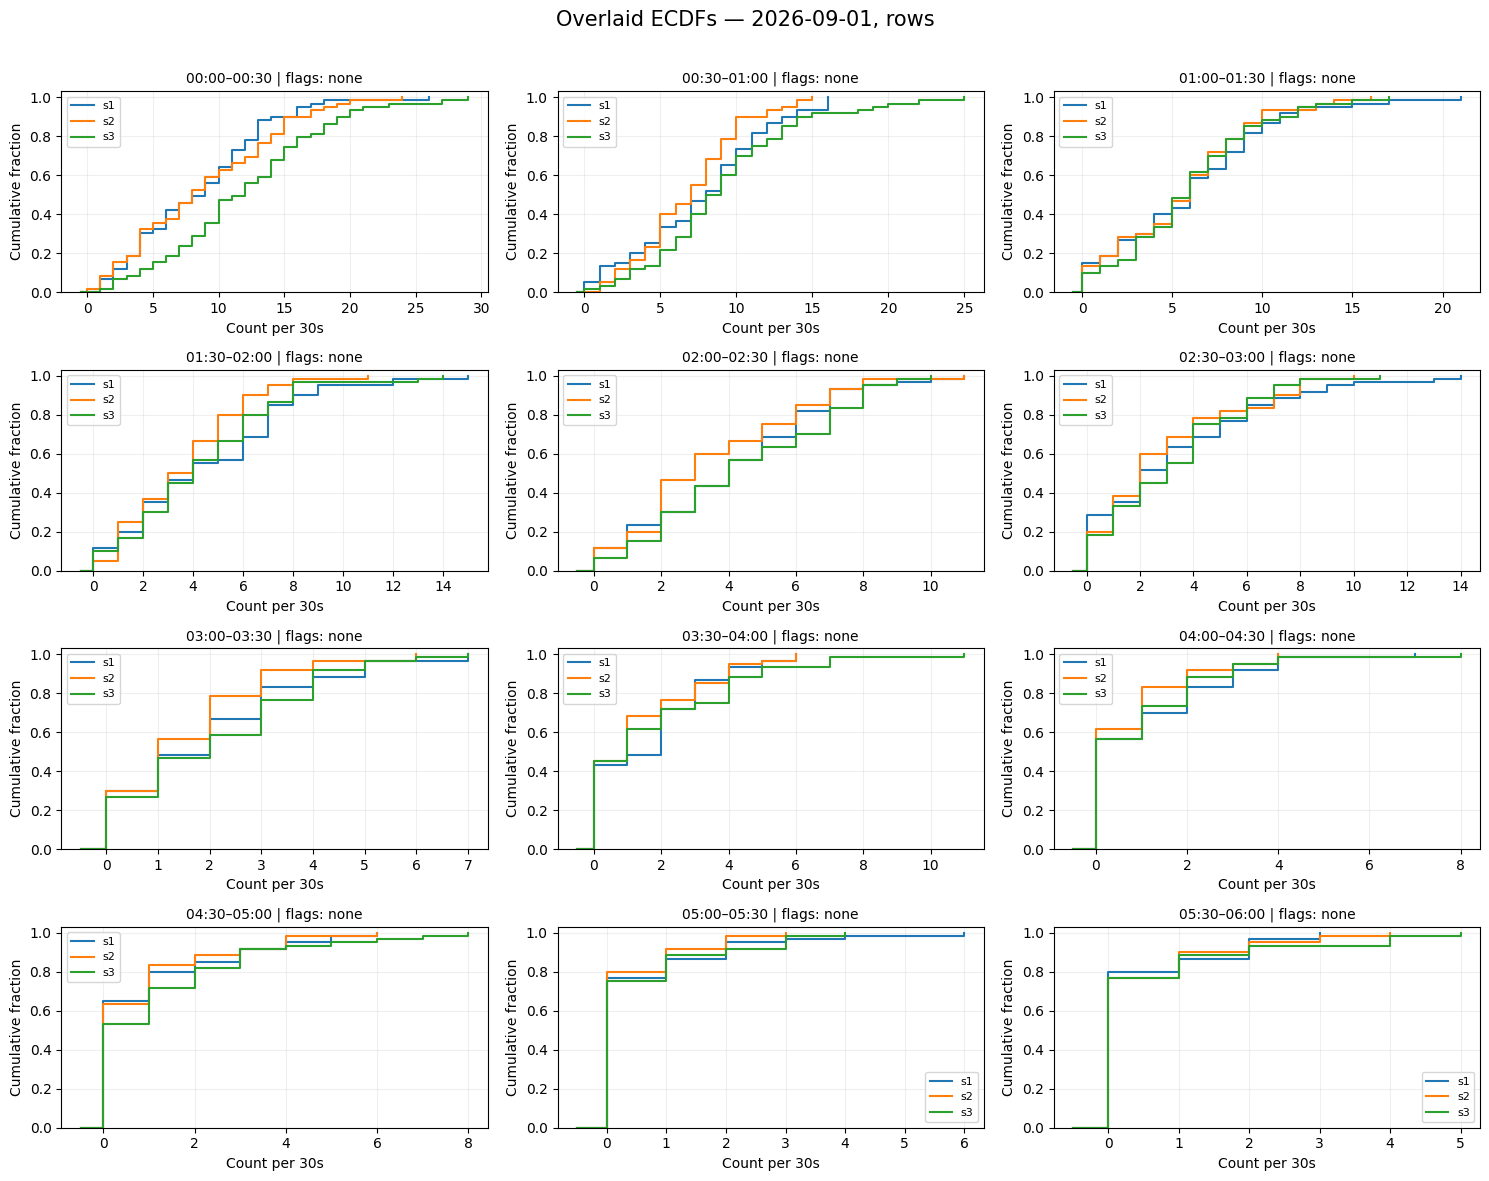

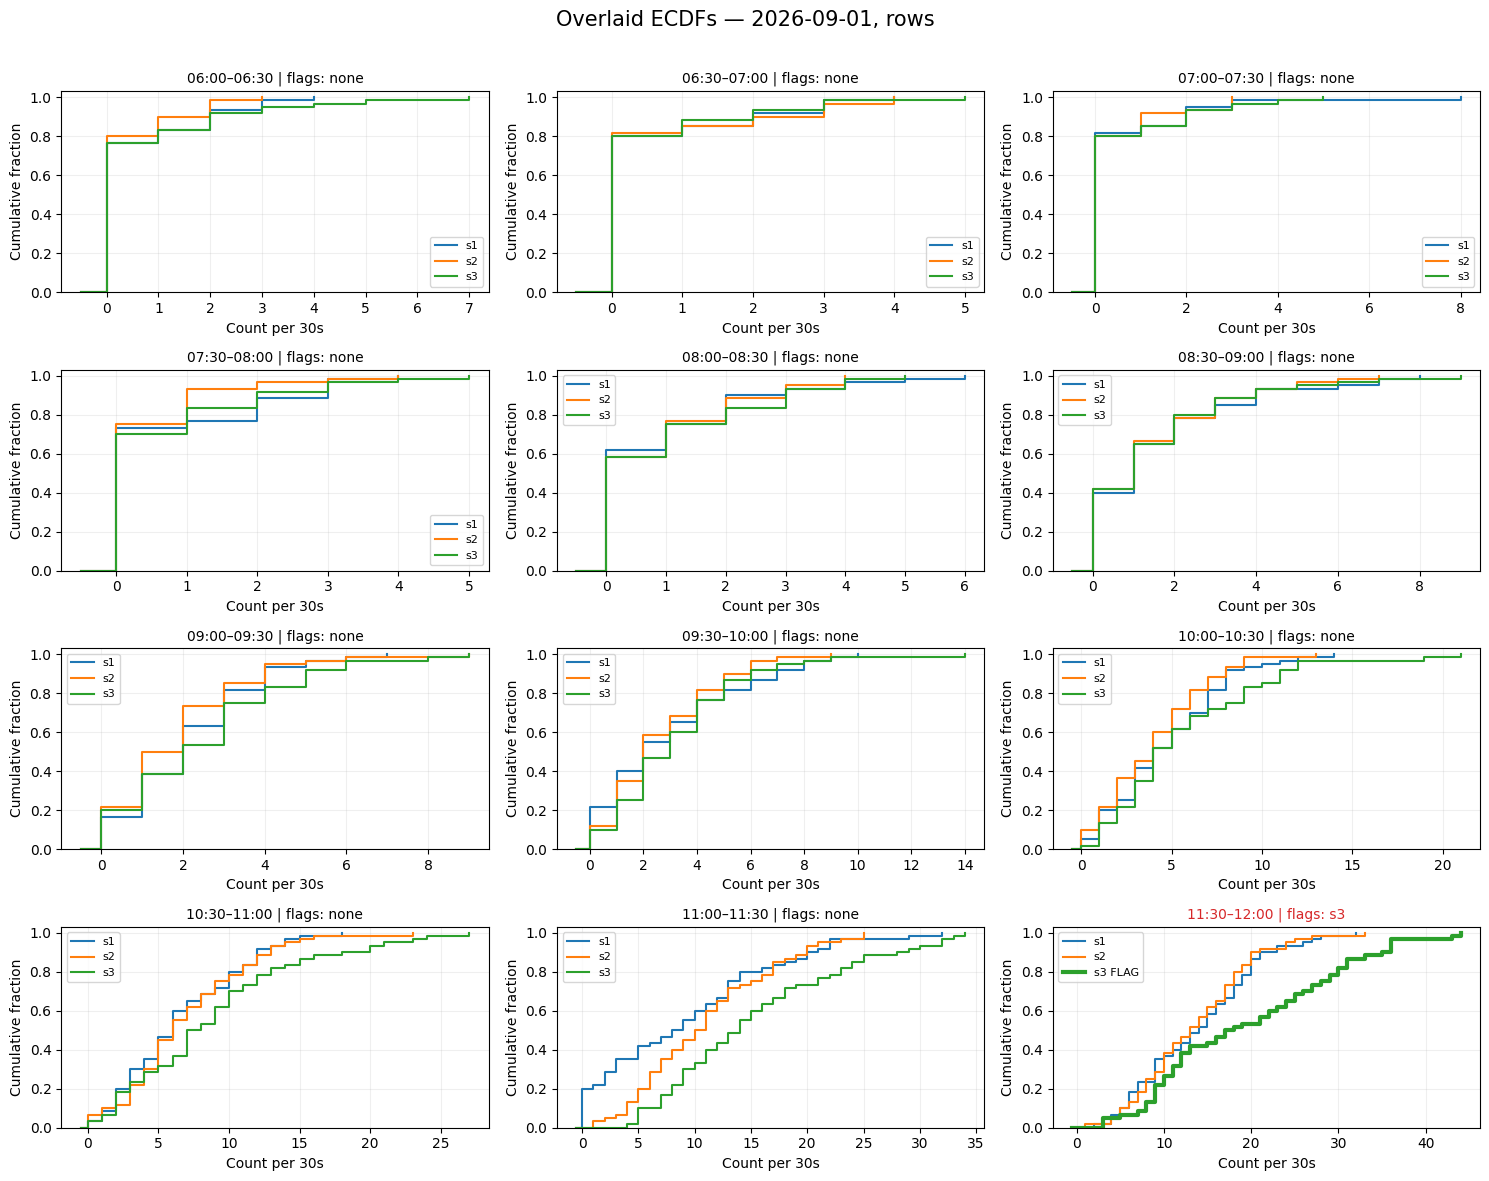

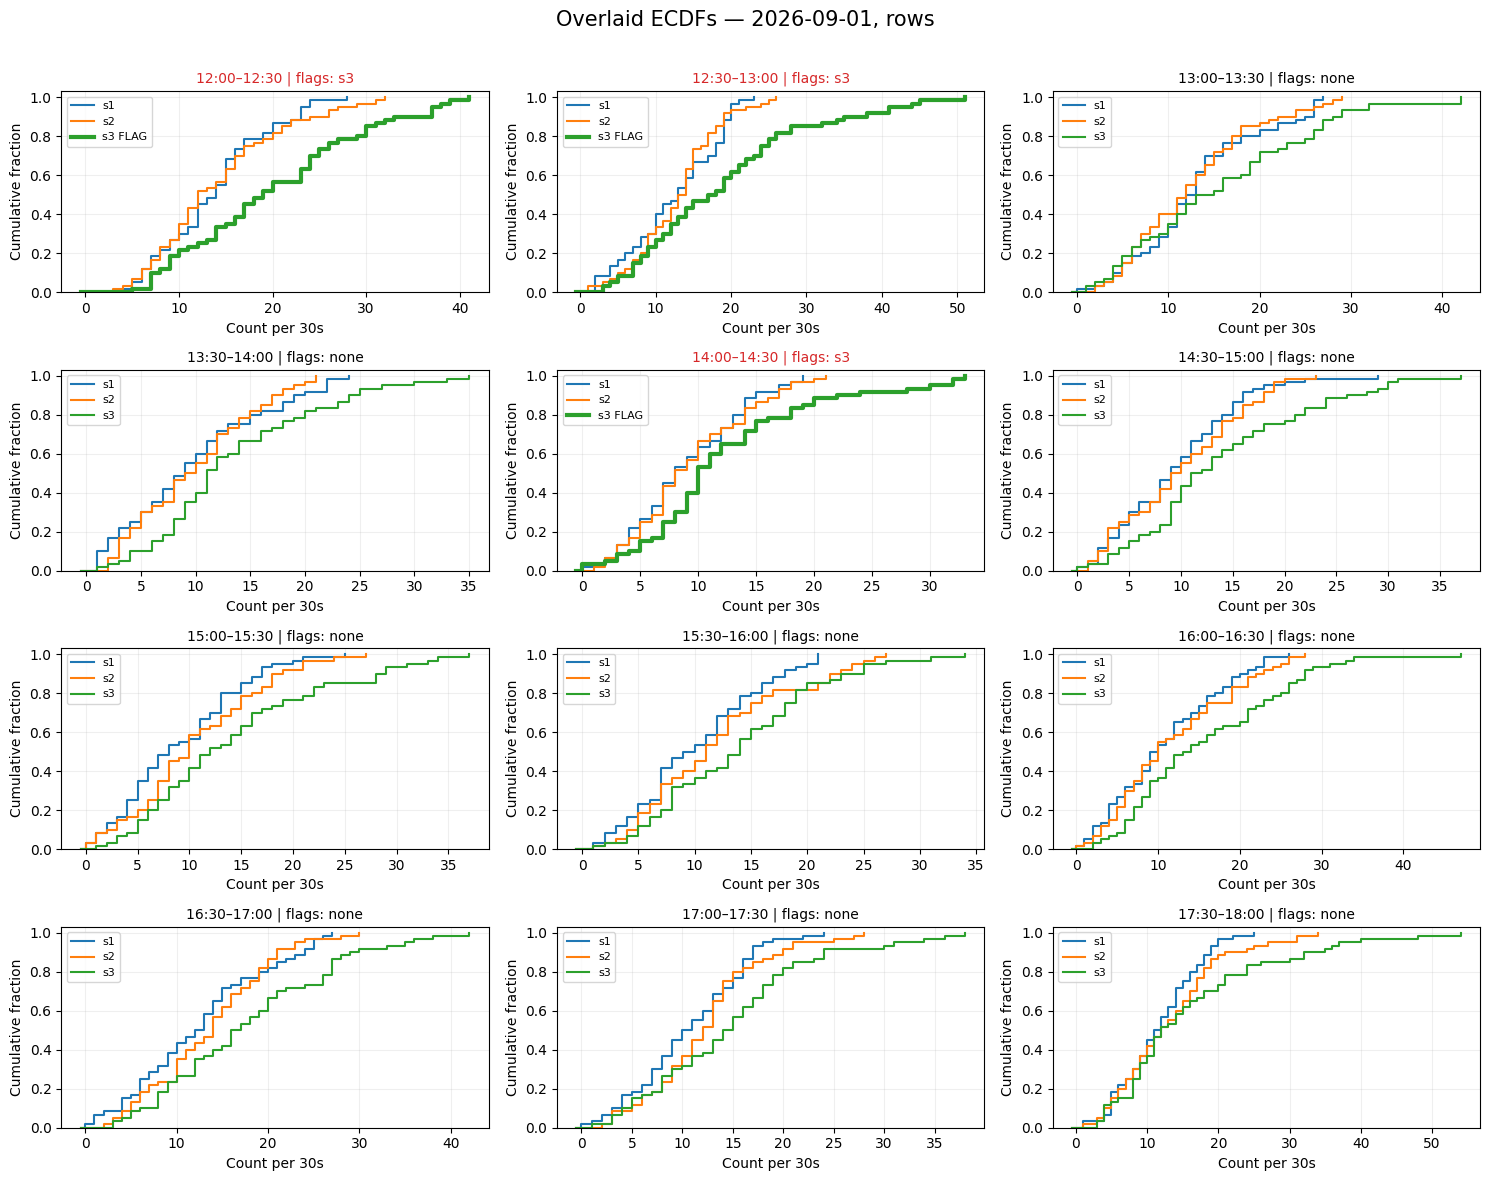

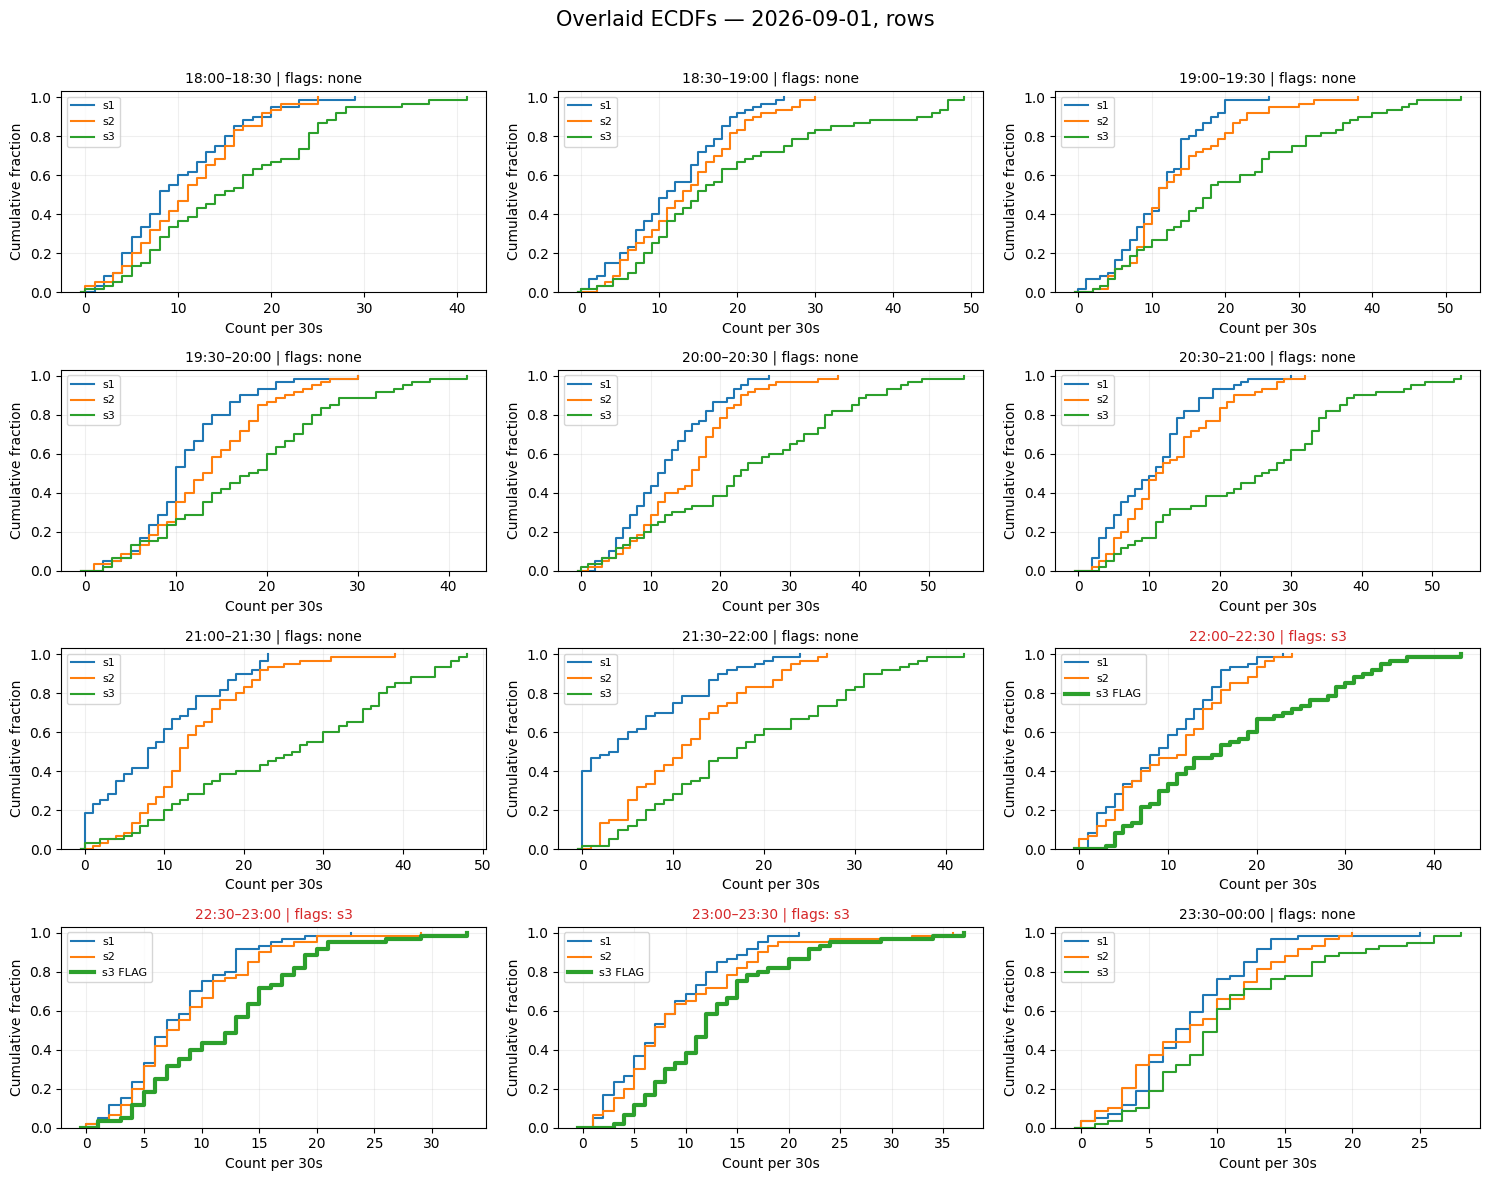

In [5]:
colors = {"s1": "tab:blue", "s2": "tab:orange", "s3": "tab:green"}
for page_start in range(0, len(metrics), 12):
    fig, axes = plt.subplots(4, 3, figsize=(15, 12))
    for ax, row in zip(axes.flat, metrics.iloc[page_start:page_start + 12].itertuples(index=False)):
        common = aligned.loc[(aligned.index >= row.window_start)
                             & (aligned.index < row.window_end)].dropna()
        if common.empty:
            ax.text(0.5, 0.5, "No common coverage", ha="center")
            continue
        for sensor in ["s1", "s2", "s3"]:
            values = np.sort(common[sensor].to_numpy())
            x = np.unique(values)
            y = np.searchsorted(values, x, side="right") / len(values)
            ax.step(np.r_[min(-0.5, x[0] - 0.5), x], np.r_[0, y],
                    where="post", label=sensor + (" FLAG" if getattr(row, f"{sensor}_flag") else ""),
                    linewidth=3 if getattr(row, f"{sensor}_flag") else 1.5,
                    color=colors[sensor])
        ax.set_title(f"{row.window_start:%H:%M}–{row.window_end:%H:%M} | flags: {row.flagged_sensors}",
                     color="tab:red" if row.flagged_sensors != "none" else "black", fontsize=10)
        ax.set_xlabel(f"Count per {BIN}")
        ax.set_ylabel("Cumulative fraction")
        ax.set_ylim(0, 1.03)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(f"Overlaid ECDFs — {DAY}, {COUNT_MODE}", fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

## Scores for each camera

Each sensor gets its own score panel. The dashed line is the score threshold; red markers also satisfy the reference-agreement condition. Crossing the dashed line alone does not guarantee a flag.

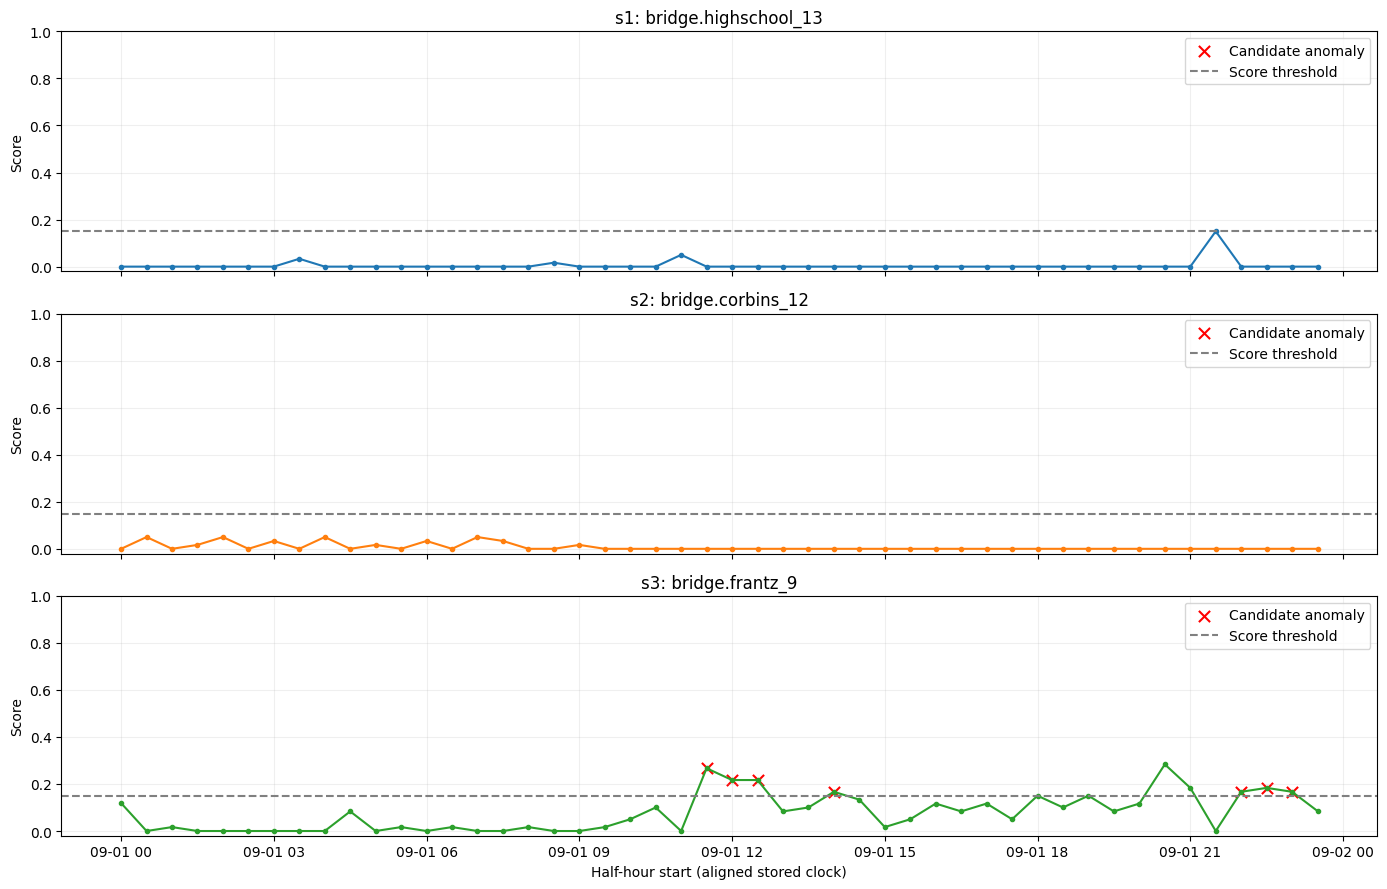

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, sensor in zip(axes, sensors):
    ax.plot(metrics["window_start"], metrics[f"{sensor}_score"], color=colors[sensor], marker=".")
    flagged = metrics[metrics[f"{sensor}_flag"]]
    ax.scatter(flagged["window_start"], flagged[f"{sensor}_score"], color="red", marker="x", s=65, label="Candidate anomaly")
    ax.axhline(SCORE_THRESHOLD, color="gray", linestyle="--", label="Score threshold")
    ax.set_title(sensor + ": " + cameras.set_index("camera").loc[sensor, "intersection"])
    ax.set_ylabel("Score")
    ax.set_ylim(-0.02, 1)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Half-hour start (aligned stored clock)")
fig.tight_layout()
plt.show()

## Pairwise distances and score heatmap

The pairwise plot helps distinguish one-camera disagreement from disagreement across the whole group. The heatmap shows all 144 camera/window scores; × marks flags.

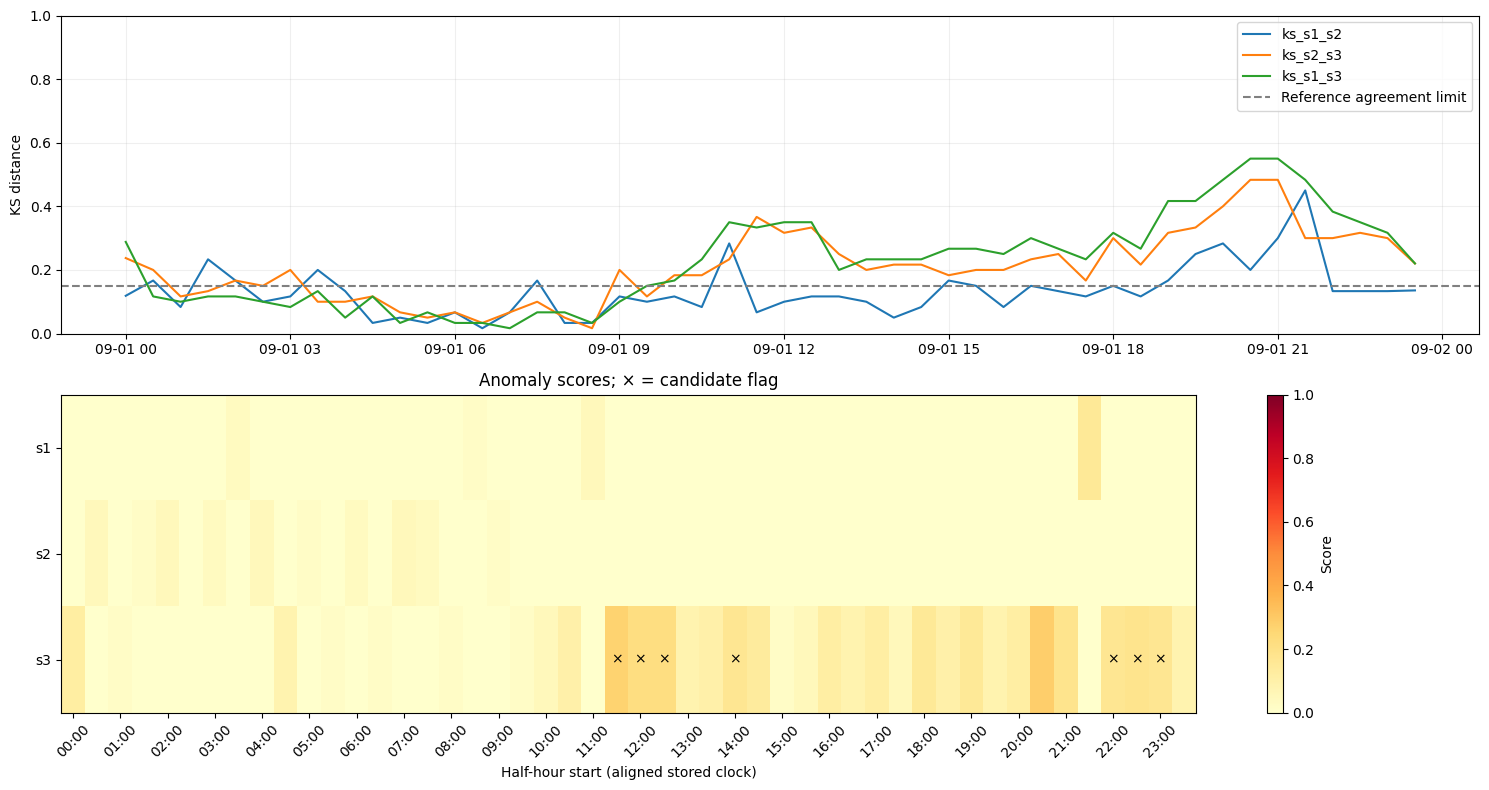

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for pair in ["ks_s1_s2", "ks_s2_s3", "ks_s1_s3"]:
    axes[0].plot(metrics["window_start"], metrics[pair], label=pair)
axes[0].axhline(REFERENCE_KS_MAX, color="gray", linestyle="--", label="Reference agreement limit")
axes[0].set_ylabel("KS distance")
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.2)
score_matrix = metrics[[f"{s}_score" for s in sensors]].to_numpy().T
im = axes[1].imshow(score_matrix, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
axes[1].set_yticks(range(3), sensors)
axes[1].set_xticks(range(0, len(metrics), 2), metrics["window_start"].dt.strftime("%H:%M").iloc[::2], rotation=45)
for y, sensor in enumerate(sensors):
    for x in np.flatnonzero(metrics[f"{sensor}_flag"].to_numpy()):
        axes[1].text(x, y, "×", ha="center", va="center", color="black")
axes[1].set_xlabel("Half-hour start (aligned stored clock)")
axes[1].set_title("Anomaly scores; × = candidate flag")
fig.colorbar(im, ax=axes[1], label="Score")
fig.tight_layout()
plt.show()

## Count levels and candidate windows

Mean counts help interpret whether the flagged camera reports more or fewer rows. Red shaded spans indicate flags. The table lists every flagged camera/window, sorted by score. An empty table means no candidates under the selected thresholds.

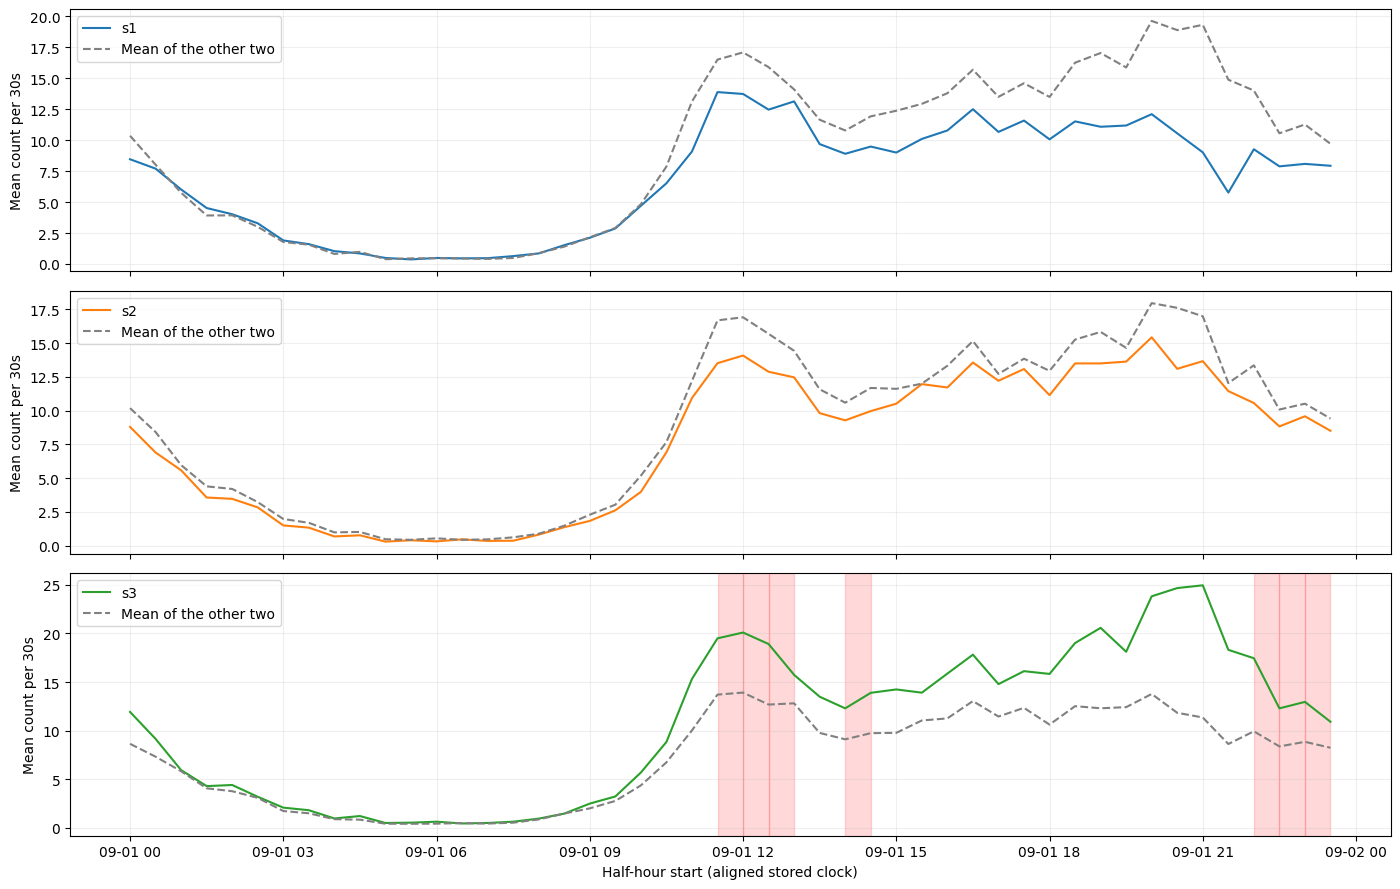

,window_start,window_end,sensor,common_bins,score,flag,ks_to_s2,ks_to_s3,reference_ks,mean_count,reference_mean,mean_ratio,zero_fraction,direction,all_silent,ks_to_s1
71,2026-09-01 11:30:00,2026-09-01 12:00:00,s3,60,0.2667,True,0.3667,NaN,0.0667,19.5000,13.7000,1.4234,0.0000,more,False,0.3333
74,2026-09-01 12:00:00,2026-09-01 12:30:00,s3,60,0.2167,True,0.3167,NaN,0.1000,20.1000,13.9083,1.4452,0.0000,more,False,0.3500
77,2026-09-01 12:30:00,2026-09-01 13:00:00,s3,60,0.2167,True,0.3333,NaN,0.1167,18.9167,12.6750,1.4924,0.0000,more,False,0.3500
137,2026-09-01 22:30:00,2026-09-01 23:00:00,s3,60,0.1833,True,0.3167,NaN,0.1333,12.2833,8.3583,1.4696,0.0000,more,False,0.3500
86,2026-09-01 14:00:00,2026-09-01 14:30:00,s3,60,0.1667,True,0.2167,NaN,0.0500,12.2833,9.0917,1.3511,0.0333,more,False,0.2333
134,2026-09-01 22:00:00,2026-09-01 22:30:00,s3,60,0.1667,True,0.3000,NaN,0.1333,17.4500,9.9167,1.7597,0.0000,more,False,0.3833
140,2026-09-01 23:00:00,2026-09-01 23:30:00,s3,60,0.1667,True,0.3000,NaN,0.1333,12.9500,8.8333,1.4660,0.0000,more,False,0.3167


In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, sensor in zip(axes, sensors):
    other_sensors = [s for s in sensors if s != sensor]
    reference = metrics[[f"{s}_mean" for s in other_sensors]].mean(axis=1)
    ax.plot(metrics["window_start"], metrics[f"{sensor}_mean"], label=sensor, color=colors[sensor])
    ax.plot(metrics["window_start"], reference, label="Mean of the other two", color="gray", linestyle="--")
    for row in metrics[metrics[f"{sensor}_flag"]].itertuples(index=False):
        ax.axvspan(row.window_start, row.window_end, color="red", alpha=0.15)
    ax.set_ylabel(f"Mean count per {BIN}")
    ax.legend()
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Half-hour start (aligned stored clock)")
plt.tight_layout()
plt.show()
flagged_windows = sensor_metrics[sensor_metrics["flag"]].sort_values("score", ascending=False)
with pd.option_context("display.max_rows", 144):
    display(flagged_windows.round(4))

## Export and verification

Save a 48-row window summary and a 144-row camera/window table. `ks_to_s1`, `ks_to_s2`, or `ks_to_s3` is blank when it would compare a camera with itself. Scores are computed from common aligned bins only. First and last windows have partial boundary coverage.

In [9]:
output_dir = DATA_FILE.parent / "ai_hack_mobility_2026"
metrics.to_csv(output_dir / f"comparison_3_windows_{DAY}_{COUNT_MODE}.csv", index=False)
sensor_metrics.to_csv(output_dir / f"comparison_3_sensors_{DAY}_{COUNT_MODE}.csv", index=False)
print(f"Saved {len(metrics)} half-hour windows and {len(sensor_metrics)} camera/window rows.")

assert len(metrics) == 48 and len(sensor_metrics) == 144
assert metrics["common_bins"].tolist() == [59] + [60] * 46 + [59]
assert ks_distance([0, 1, 2], [0, 1, 2]) == 0
assert ks_distance([0, 0], [10, 10]) == 1
# A separated distribution is correctly identified regardless of camera label.
for odd_sensor in sensors:
    samples = {s: [10, 10, 10] if s == odd_sensor else [0, 0, 0] for s in sensors}
    for sensor in sensors:
        a, b = [s for s in sensors if s != sensor]
        score, flag = score_and_flag(ks_distance(samples[sensor], samples[a]),
                                    ks_distance(samples[sensor], samples[b]),
                                    ks_distance(samples[a], samples[b]))
        assert flag == (sensor == odd_sensor)
assert score_and_flag(0, 0, 0) == (0, False)
assert not score_and_flag(1, 1, 1)[1]  # No consensus: do not attribute a fault.
assert sensor_metrics["score"].dropna().between(0, 1).all()

Saved 48 half-hour windows and 144 camera/window rows.
